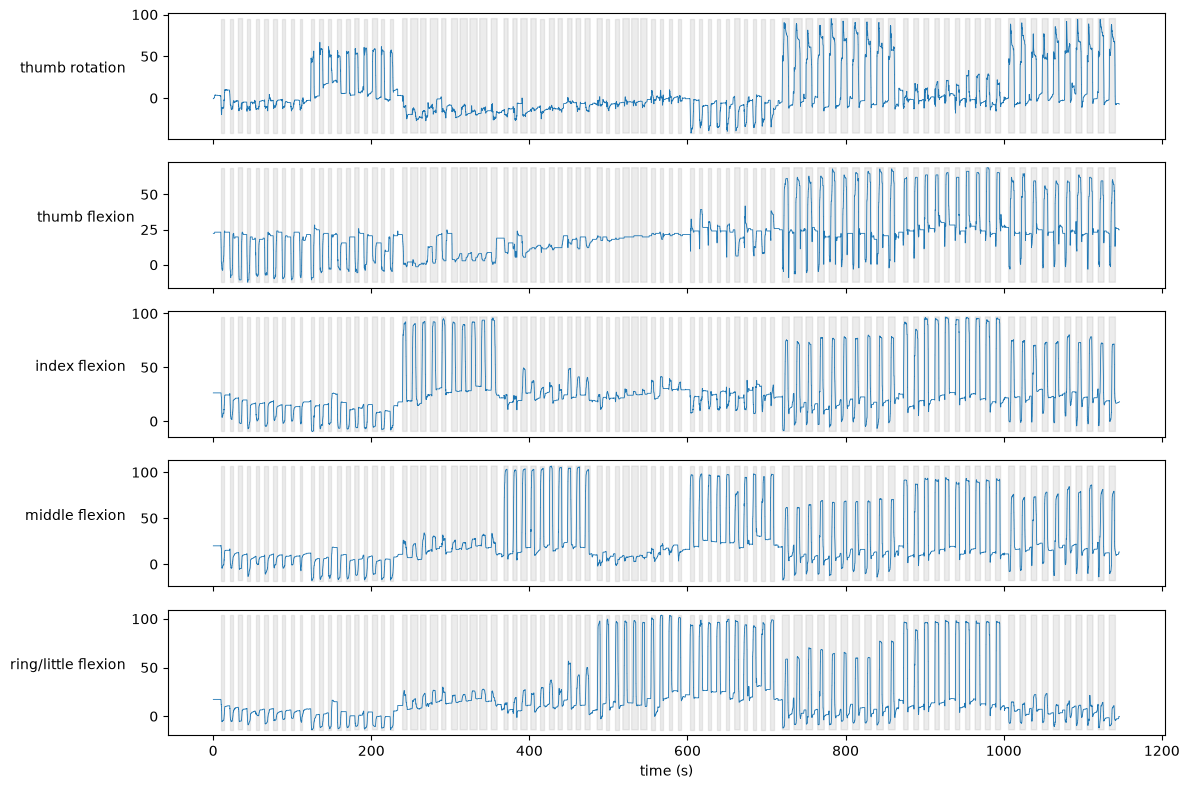

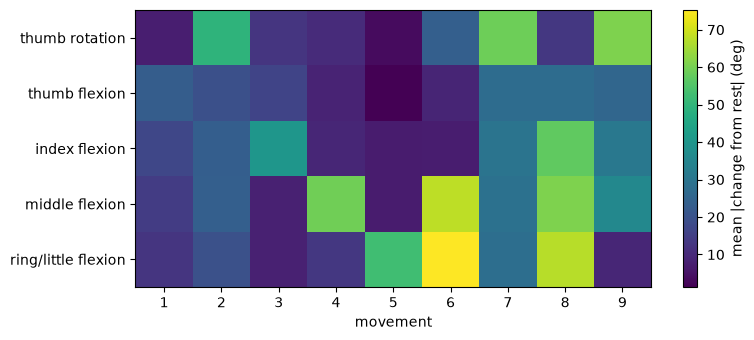

In [1]:
%load_ext autoreload
%autoreload 2
import sys; sys.path.append(r"D:\emg-project\src")
import numpy as np, matplotlib.pyplot as plt
from emgproc import to_doa, DOA_NAMES

d = np.load(r"D:\emg-project\data\processed\S1_E1_A1.npz")
doa, t, rs = to_doa(d["glove"]), d["t"], d["restim"]

# A. The 5 finger DoAs across the whole session (grey = movement periods)
fig, ax = plt.subplots(5, 1, sharex=True, figsize=(12, 8))
for j in range(5):
    ax[j].plot(t, doa[:, j], lw=0.6)
    ax[j].fill_between(t, doa[:, j].min(), doa[:, j].max(), where=rs > 0, color="grey", alpha=0.15)
    ax[j].set_ylabel(DOA_NAMES[j], rotation=0, ha="right")
ax[-1].set_xlabel("time (s)"); plt.tight_layout(); plt.show()

# B. Which fingers move in which movement? (average change from rest)
rest = doa[rs == 0].mean(axis=0)
change = np.array([np.abs(doa[rs == m] - rest).mean(axis=0) for m in range(1, 10)])
plt.figure(figsize=(8, 3.5))
plt.imshow(change.T, aspect="auto"); plt.colorbar(label="mean |change from rest| (deg)")
plt.xticks(range(9), range(1, 10)); plt.yticks(range(5), DOA_NAMES)
plt.xlabel("movement"); plt.tight_layout(); plt.show()